# 03 · Exploratory Analysis

**Purpose:** Compare pollutant levels at each stage of the plant (E input, P primary settler, D secondary settler, S output).

**Research question served:** Q1: how do wastewater quality parameters vary across the treatment stages?

**Status:** in progress.

## 1. Setup
We make the project files available and import pandas, numpy and matplotlib.

In [1]:
import os
# Colab: clone the repo. Codespaces: we are already inside it.
if not os.path.exists("data/processed"):
    if os.path.exists("../data/processed"):
        os.chdir("..")
    else:
        !git clone https://github.com/davis-mironga/wastewater-treatment-analytics.git
        %cd wastewater-treatment-analytics

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 2. Load the cleaned data
We load the file made by `src/cleaning.py`: 527 rows, sorted by date, `?` read as missing. Nothing has been imputed or removed. COD (`DQO`) has no measurement at the primary settler input, so it has three stages, not four.

Per the analysis plan we summarise with the median (`50%`) and quartiles, because wastewater data tends to be skewed.

In [2]:
df = pd.read_csv("data/processed/water_treatment_clean.csv",
                 parse_dates=["date_parsed"])
print(df.shape)
print("In date order?", df["date_parsed"].is_monotonic_increasing)

stages = ["E", "P", "D", "S"]
for v in ["DBO", "DQO", "SS", "PH"]:
    cols_v = [f"{v}-{s}" for s in stages if f"{v}-{s}" in df.columns]
    print("\n", v)
    print(df[cols_v].describe().loc[["count", "25%", "50%", "75%"]].round(1).to_string())

(527, 41)
In date order? True

 DBO
       DBO-E  DBO-P  DBO-D  DBO-S
count  504.0  487.0  499.0  504.0
25%    146.8  153.0   97.0   14.0
50%    182.5  197.0  119.0   18.0
75%    223.0  243.0  148.0   23.0

 DQO
       DQO-E  DQO-D  DQO-S
count  521.0  518.0  509.0
25%    325.0  220.0   64.0
50%    400.0  274.0   84.0
75%    478.0  325.0  101.0

 SS
        SS-E   SS-P   SS-D   SS-S
count  526.0  527.0  525.0  522.0
25%    170.0  184.0   78.0   14.0
50%    196.0  220.0   90.0   19.0
75%    242.0  272.0  106.0   24.0

 PH
        PH-E   PH-P   PH-D   PH-S
count  527.0  527.0  527.0  526.0
25%      7.6    7.7    7.7    7.6
50%      7.8    7.8    7.8    7.7
75%      8.0    8.0    7.9    7.8


### What we see
Medians fall sharply from the primary settler input to the plant output: BOD 197 → 119 → 18, suspended solids 220 → 90 → 19, COD 400 → 274 → 84 (no COD at the primary settler). Between plant input and primary settler input, values barely change (BOD 182.5 → 197), and the cause is not given in the dictionary. pH is stable at 7.7 to 7.8. The output quartiles are much narrower than the input quartiles. These are medians of each column separately, so they are not paired same-day comparisons; removal efficiency (notebook 04) uses paired rows. Units are not stated in the dictionary.

## 3. Full spread at each stage
Boxplots show the median, quartiles and extreme days. Points beyond the whiskers are unusual values at that stage. They are statistical outliers, not confirmed pollution events.

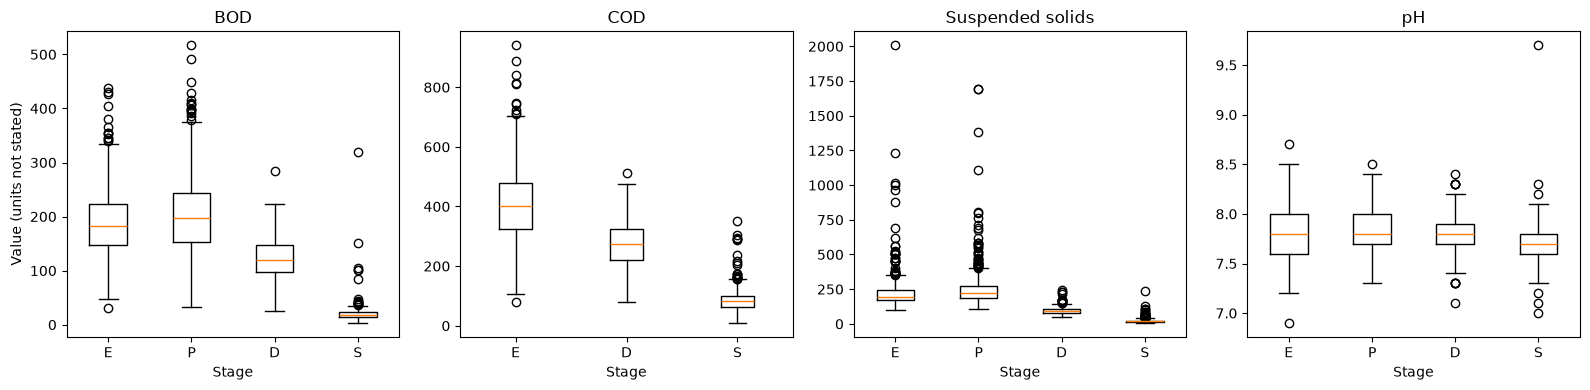

In [3]:
import os
os.makedirs("reports/figures", exist_ok=True)
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (v, title) in zip(axes, [("DBO","BOD"),("DQO","COD"),("SS","Suspended solids"),("PH","pH")]):
    cs = [f"{v}-{s}" for s in ["E","P","D","S"] if f"{v}-{s}" in df.columns]
    ax.boxplot([df[c].dropna() for c in cs], tick_labels=[c.split("-")[1] for c in cs])
    ax.set_title(title)
    ax.set_xlabel("Stage")
axes[0].set_ylabel("Value (units not stated)")
plt.tight_layout()
plt.savefig("reports/figures/stage_boxplots.png", dpi=150)
plt.show()

### What we see
*(Write after viewing the figure.)*